1. Data Loading & Initial EDA 
Dataset Size: 1170 rows and 22 columns



,patient_id,age,sex,bmi,diabetes,hypertension,smoking,family_history,prior_mi,acs_type,...,killip_class,troponin_ng_ml,ckmb_u_l,creatinine_mg_dl,glucose_mmol_l,ldl_mmol_l,hdl_mmol_l,lvef_percent,reperfusion,mace
0,P0001,60,Female,21.0,0,0,0,0,1,STEMI,...,1,0.38,10.7,1.12,8.7,2.34,1.08,57.0,Thrombolysis,0
1,P0002,44,Female,18.1,0,0,1,0,0,STEMI,...,1,0.27,5.0,1.15,7.4,2.44,0.79,37.0,NaN,0
2,P0003,65,Female,25.0,0,0,0,0,0,STEMI,...,2,19.01,15.3,1.22,4.0,3.78,1.15,49.0,Primary PCI,0
3,P0004,67,Female,21.6,1,1,0,0,0,Unstable angina,...,1,0.06,85.9,0.75,7.0,3.13,0.59,NaN,NaN,1
4,P0005,34,Male,25.1,0,0,0,0,0,Unstable angina,...,2,0.05,88.6,1.09,9.2,2.64,0.93,44.0,NaN,0



Total Duplicate Rows: 0

Null Value Counts in Raw Data:


,Null_Count,Null_Percentage (%)
Feature,,
troponin_ng_ml,38,3.25
ckmb_u_l,45,3.85
ldl_mmol_l,41,3.50
hdl_mmol_l,32,2.74
lvef_percent,42,3.59
reperfusion,532,45.47


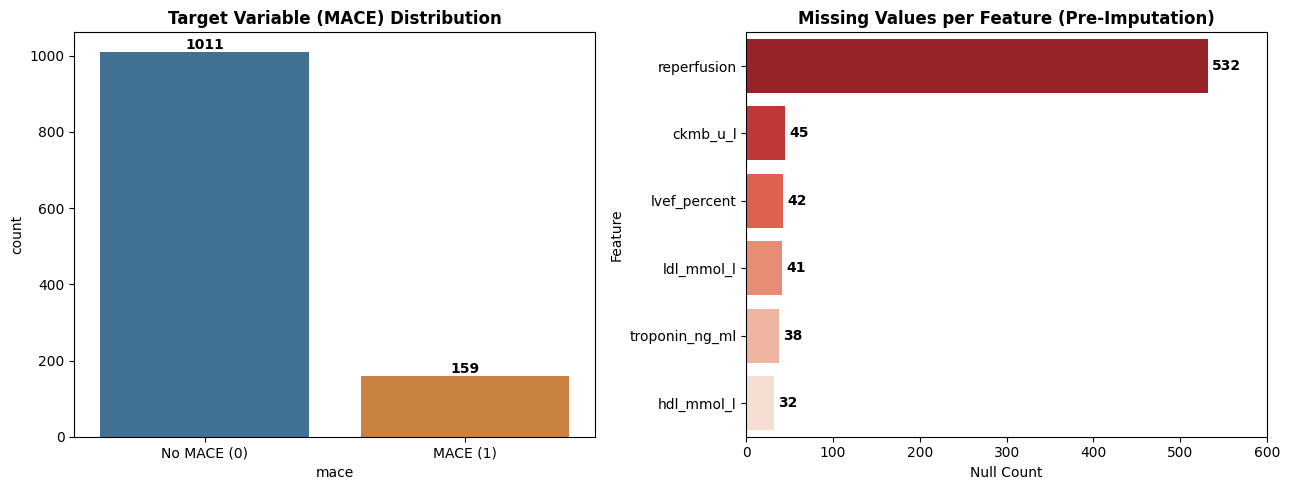

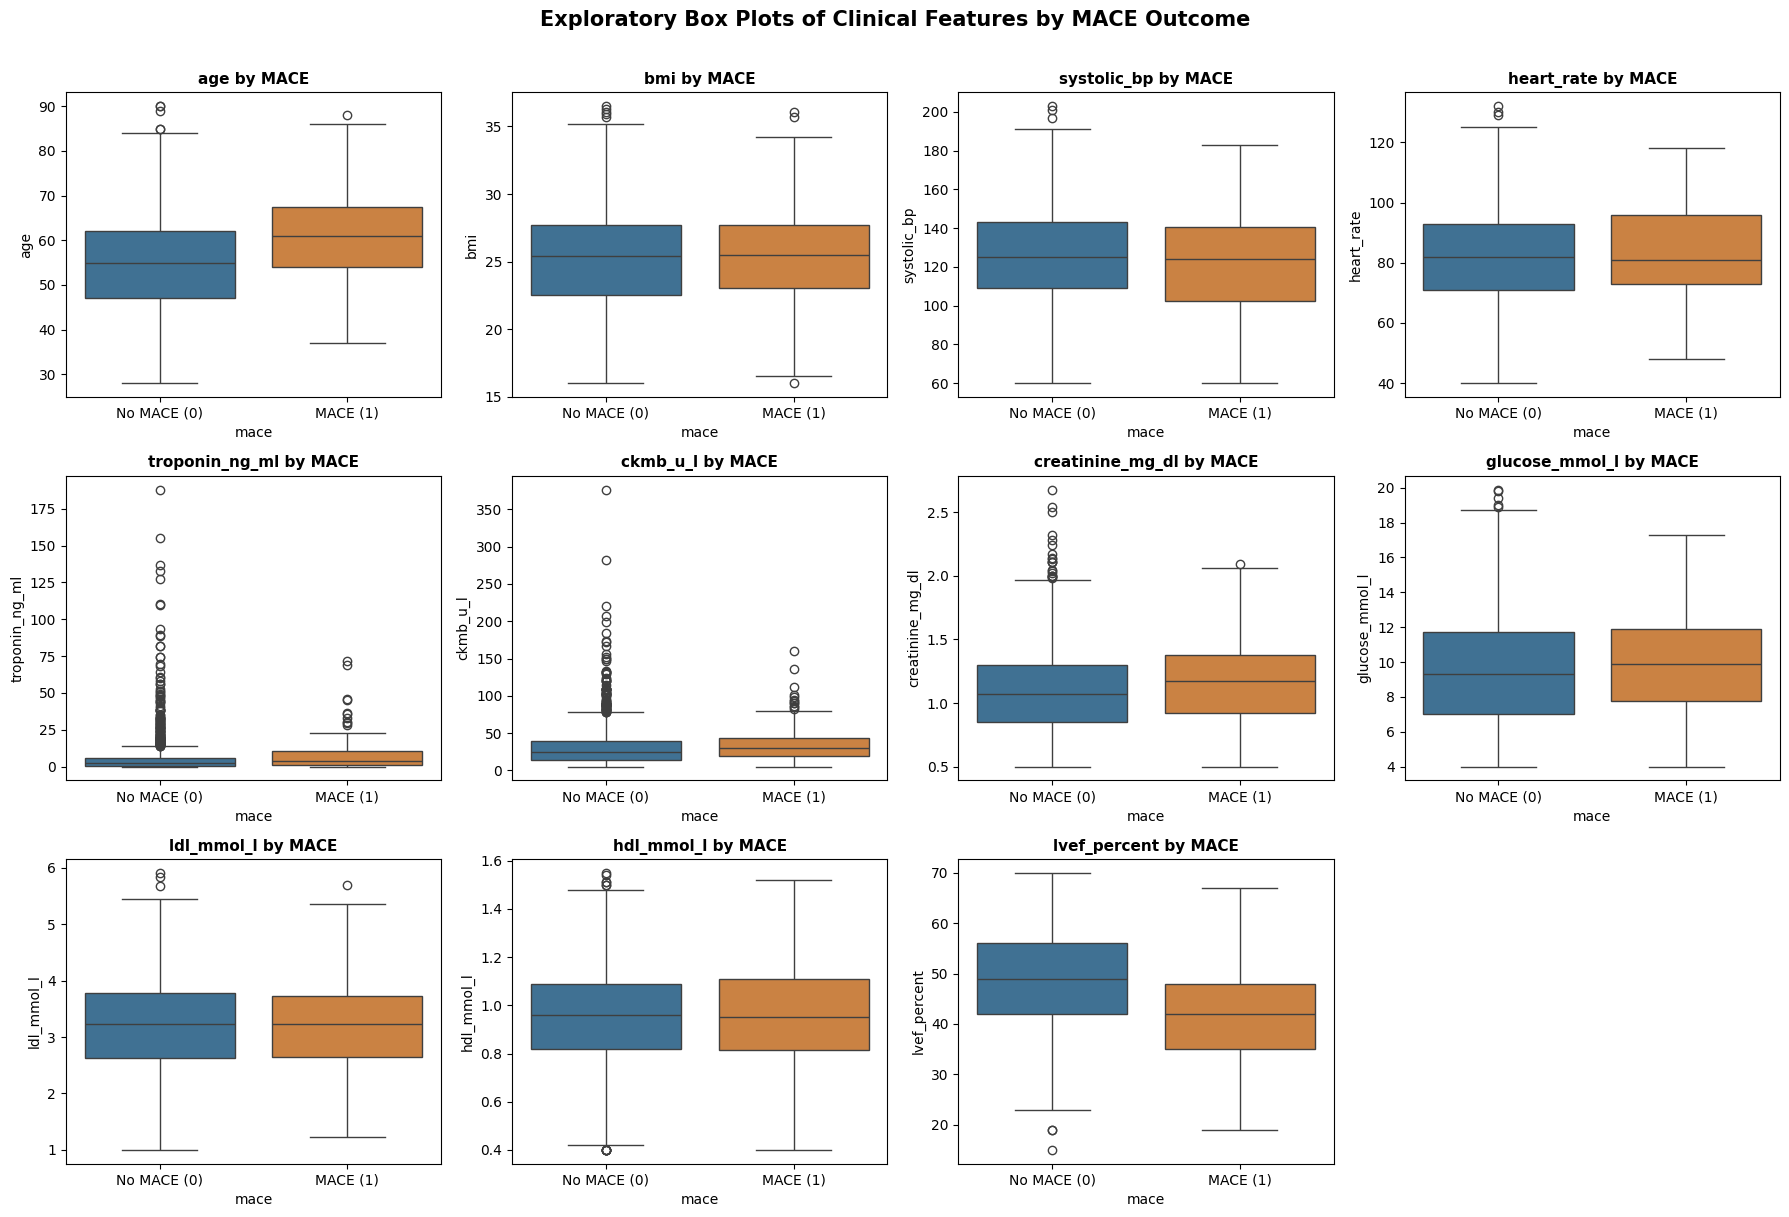

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

print("1. Data Loading & Initial EDA ")
raw_dataset = pd.read_csv('BMU_DATA.csv')

print(f"Dataset Size: {raw_dataset.shape[0]} rows and {raw_dataset.shape[1]} columns\n")
display(raw_dataset.head())

# Check Duplicates and Nulls on Raw Data
null_counts = raw_dataset.isnull().sum().to_frame(name='Null_Count')
null_counts['Null_Percentage (%)'] = (raw_dataset.isnull().sum() / len(raw_dataset) * 100).round(2)
null_counts.index.name = 'Feature'
print(f"\nTotal Duplicate Rows: {raw_dataset.duplicated().sum()}")
print("\nNull Value Counts in Raw Data:")
display(null_counts[null_counts['Null_Count'] > 0])

# Visualize Target Variable & Missing Data
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax1 = sns.countplot(x='mace', hue='mace', data=raw_dataset, palette=['#3274A1', '#E1812C'], ax=axes[0], legend=False)
for container in ax1.containers:
    ax1.bar_label(container, fontweight='bold')
axes[0].set_title('Target Variable (MACE) Distribution', fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No MACE (0)', 'MACE (1)'])

missing_only = raw_dataset.isnull().sum()[raw_dataset.isnull().sum() > 0].sort_values(ascending=False)
ax2 = sns.barplot(x=missing_only.values, y=missing_only.index, hue=missing_only.index, palette='Reds_r', ax=axes[1], legend=False)
for container in ax2.containers:
    ax2.bar_label(container, fontweight='bold', padding=3)
axes[1].set_title('Missing Values per Feature (Pre-Imputation)', fontweight='bold')
axes[1].set_xlabel('Null Count')
axes[1].set_xlim(0, 600)
plt.tight_layout()
plt.show()

eda_df = raw_dataset.drop(columns=['patient_id'], errors='ignore').copy()
eda_df['reperfusion'] = eda_df['reperfusion'].fillna('None')
is_stemi_eda = (eda_df['acs_type'] == 'STEMI').astype(int)
lvef_eda = np.clip(
    52.0 - 3.5 * (eda_df['killip_class'] - 1) - 4.0 * (eda_df['heart_rate'] / eda_df['systolic_bp']) - 5.1 * is_stemi_eda,
    15.0, 70.0
)
eda_df['lvef_percent'] = eda_df['lvef_percent'].fillna(lvef_eda).round(1)
for col in ['troponin_ng_ml', 'ckmb_u_l', 'ldl_mmol_l', 'hdl_mmol_l']:
    eda_df[col] = eda_df[col].fillna(eda_df.groupby('acs_type')[col].transform('median'))

# Box Plots of Clinical Features vs MACE
continuous_features = [
    'age', 'bmi', 'systolic_bp', 'heart_rate', 'troponin_ng_ml',
    'ckmb_u_l', 'creatinine_mg_dl', 'glucose_mmol_l', 'ldl_mmol_l',
    'hdl_mmol_l', 'lvef_percent'
]
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(continuous_features):
    sns.boxplot(x='mace', y=col, hue='mace', data=eda_df, palette=['#3274A1', '#E1812C'], ax=axes[i], legend=False)
    axes[i].set_title(f'{col} by MACE', fontsize=11, fontweight='bold')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['No MACE (0)', 'MACE (1)'])
axes[-1].axis('off')
plt.suptitle('Exploratory Box Plots of Clinical Features by MACE Outcome', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Exploratory Pearson Correlation Heatmap


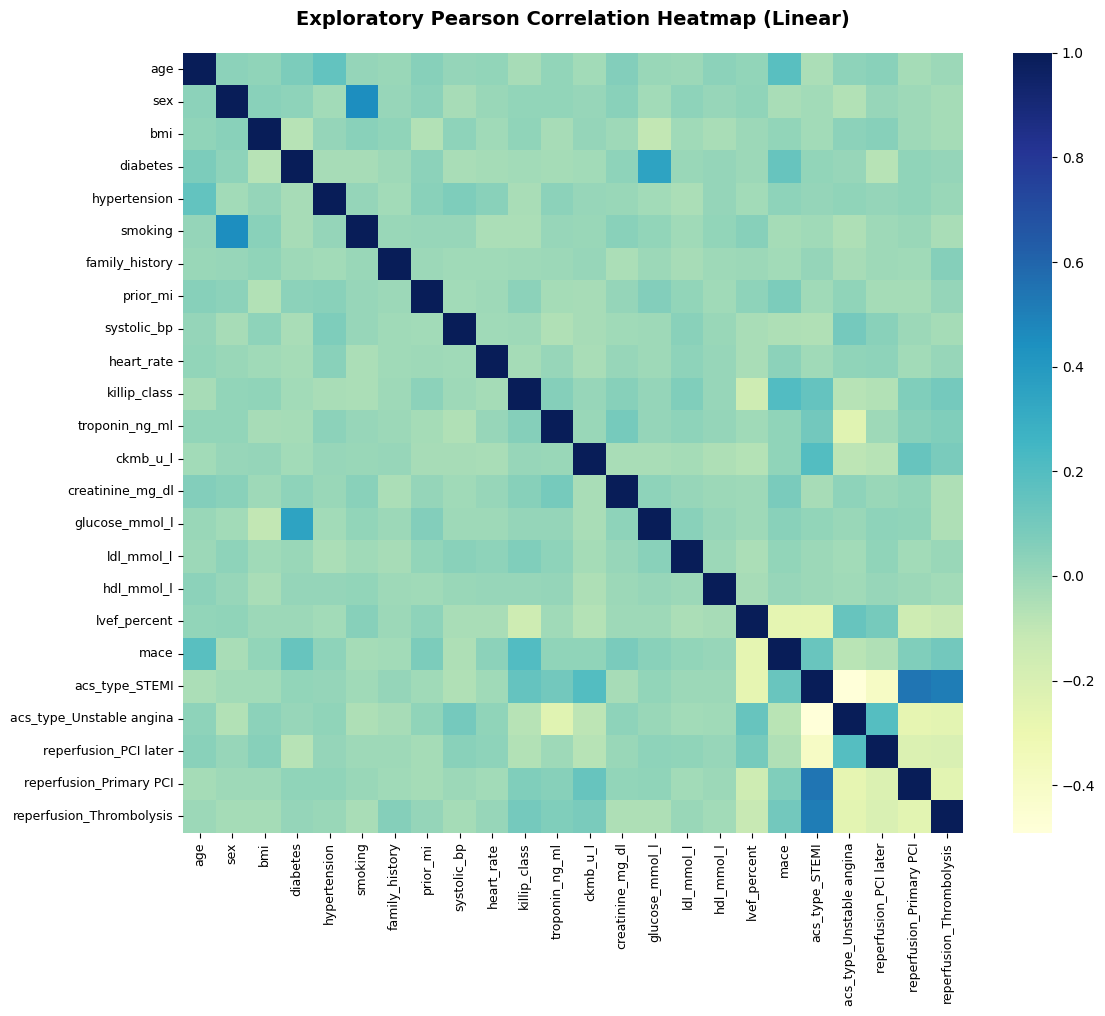


Exploratory Multicollinearity (Centered VIF) Check


,Feature,VIF_Score
0,acs_type_STEMI,4.609041
1,reperfusion_Primary PCI,3.094166
2,reperfusion_Thrombolysis,3.000794
3,acs_type_Unstable angina,1.410750
4,smoking,1.280478
5,sex,1.280408
6,reperfusion_PCI later,1.205168
7,glucose_mmol_l,1.179009
8,diabetes,1.178486
9,lvef_percent,1.108914



Exploratory Spearman Rank Correlation with MACE


,Spearman_Correlation
mace,1.000000
killip_class,0.187714
age,0.182614
diabetes,0.141124
acs_type_STEMI,0.137595
troponin_ng_ml,0.109713
reperfusion_Thrombolysis,0.107062
ckmb_u_l,0.085941
creatinine_mg_dl,0.083673
prior_mi,0.077936


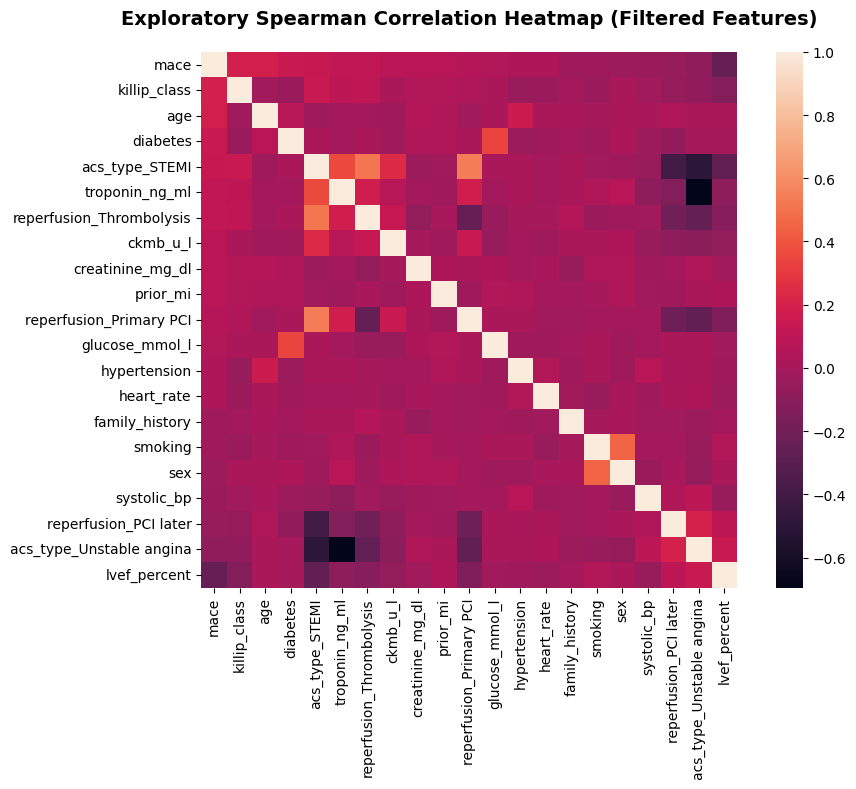

In [ ]:
# Encode the isolated EDA copy to inspect Pearson, VIF, and Spearman patterns visually
eda_encoded = eda_df.copy()
eda_encoded['sex'] = LabelEncoder().fit_transform(eda_encoded['sex'])
eda_encoded = pd.get_dummies(eda_encoded, columns=['acs_type', 'reperfusion'], drop_first=True, dtype=int)

print("Exploratory Pearson Correlation Heatmap")
plt.figure(figsize=(12, 10))
sns.heatmap(eda_encoded.corr(method='pearson'), cmap='YlGnBu', annot=False, square=True)
plt.title('Exploratory Pearson Correlation Heatmap (Linear)', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

print("\nExploratory Multicollinearity (Centered VIF) Check")
X_eda_const = add_constant(eda_encoded.drop(columns=['mace']))
vif_eda = pd.DataFrame({
    "Feature": X_eda_const.columns,
    "VIF_Score": [variance_inflation_factor(X_eda_const.values, i) for i in range(X_eda_const.shape[1])]
})
vif_eda = vif_eda[vif_eda["Feature"] != "const"].sort_values(by='VIF_Score', ascending=False).reset_index(drop=True)
display(vif_eda)

print("\nExploratory Spearman Rank Correlation with MACE")
spearman_eda = eda_encoded.corr(method='spearman')['mace'].sort_values(ascending=False)
display(spearman_eda.to_frame(name='Spearman_Correlation'))

plt.figure(figsize=(10, 8))
kept_eda_cols = spearman_eda[abs(spearman_eda) >= 0.02].index.tolist()
sns.heatmap(eda_encoded[kept_eda_cols].corr(method='spearman'), cmap='rocket', annot=False, square=True)
plt.title('Exploratory Spearman Correlation Heatmap (Filtered Features)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

Starting 100% Leak-Free 5-Fold Stratified Cross-Validation...
Processing Fold 1 (Leak-Free)...
Processing Fold 2 (Leak-Free)...
Processing Fold 3 (Leak-Free)...
Processing Fold 4 (Leak-Free)...
Processing Fold 5 (Leak-Free)...

Final 100% Leak-Free Model Comparison (5-Fold CV)


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.8034,0.3574,0.5097,0.4152,0.7695,0.3947
Random Forest,0.7821,0.3272,0.5222,0.3974,0.7691,0.3765
Gradient Boosting (XGBoost),0.7632,0.2977,0.4978,0.3659,0.7538,0.3684
Support Vector Machine (SVM),0.6496,0.2387,0.7113,0.3539,0.7309,0.3294


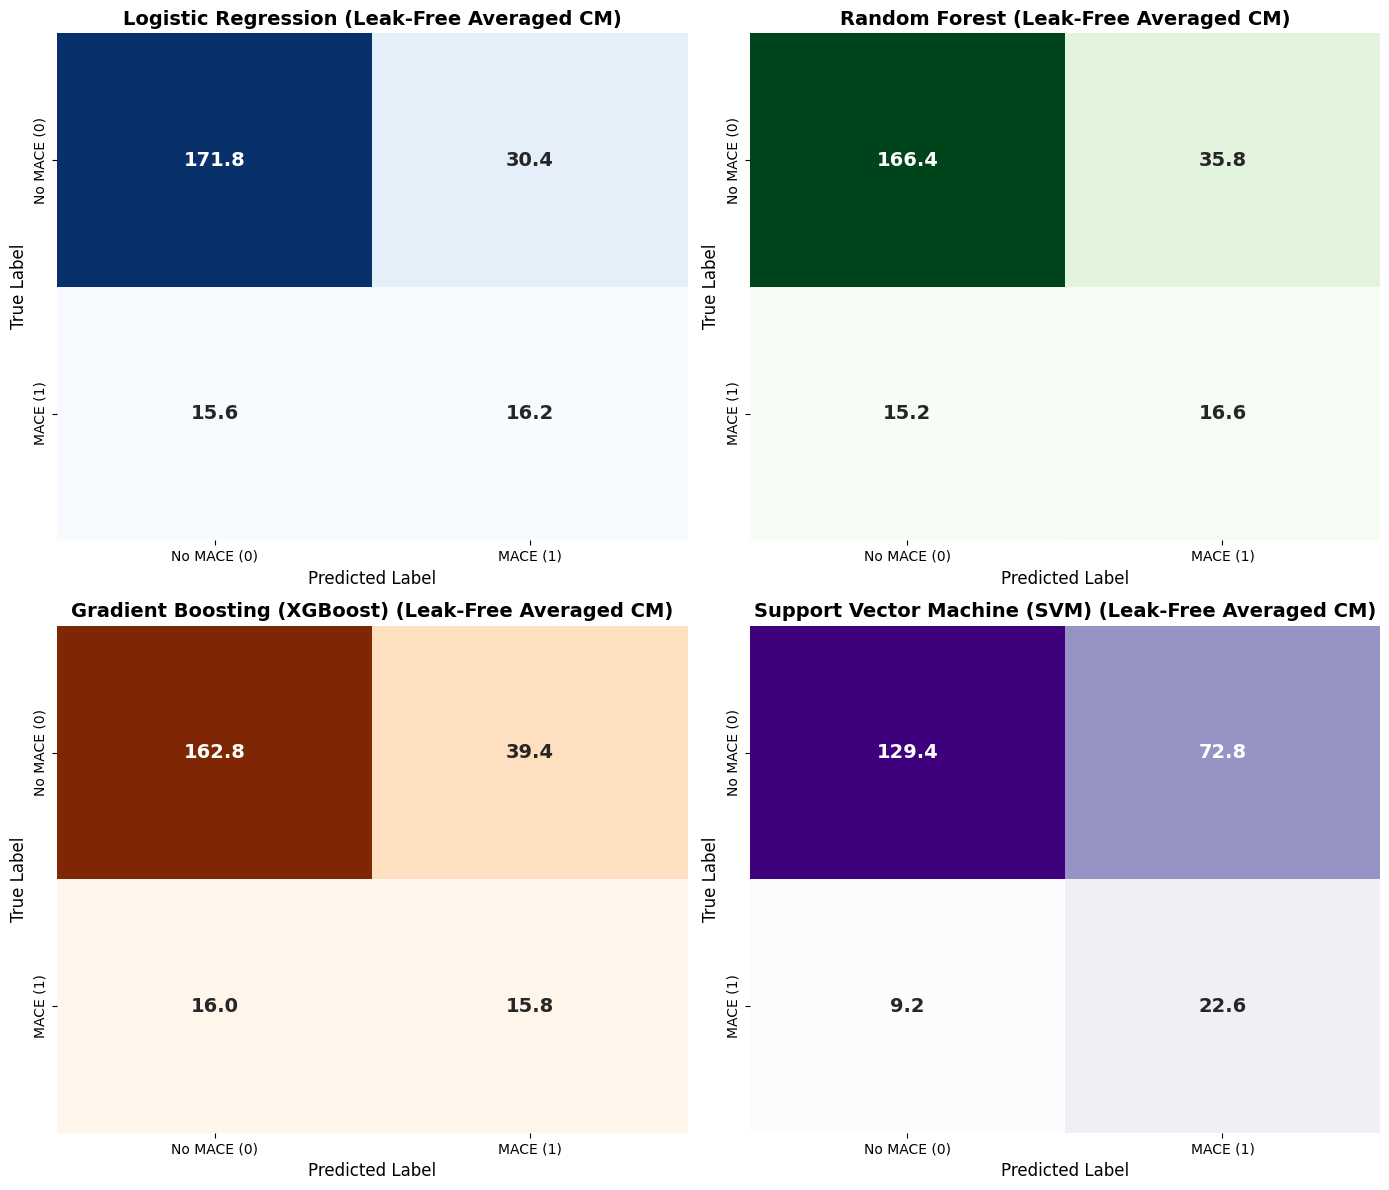

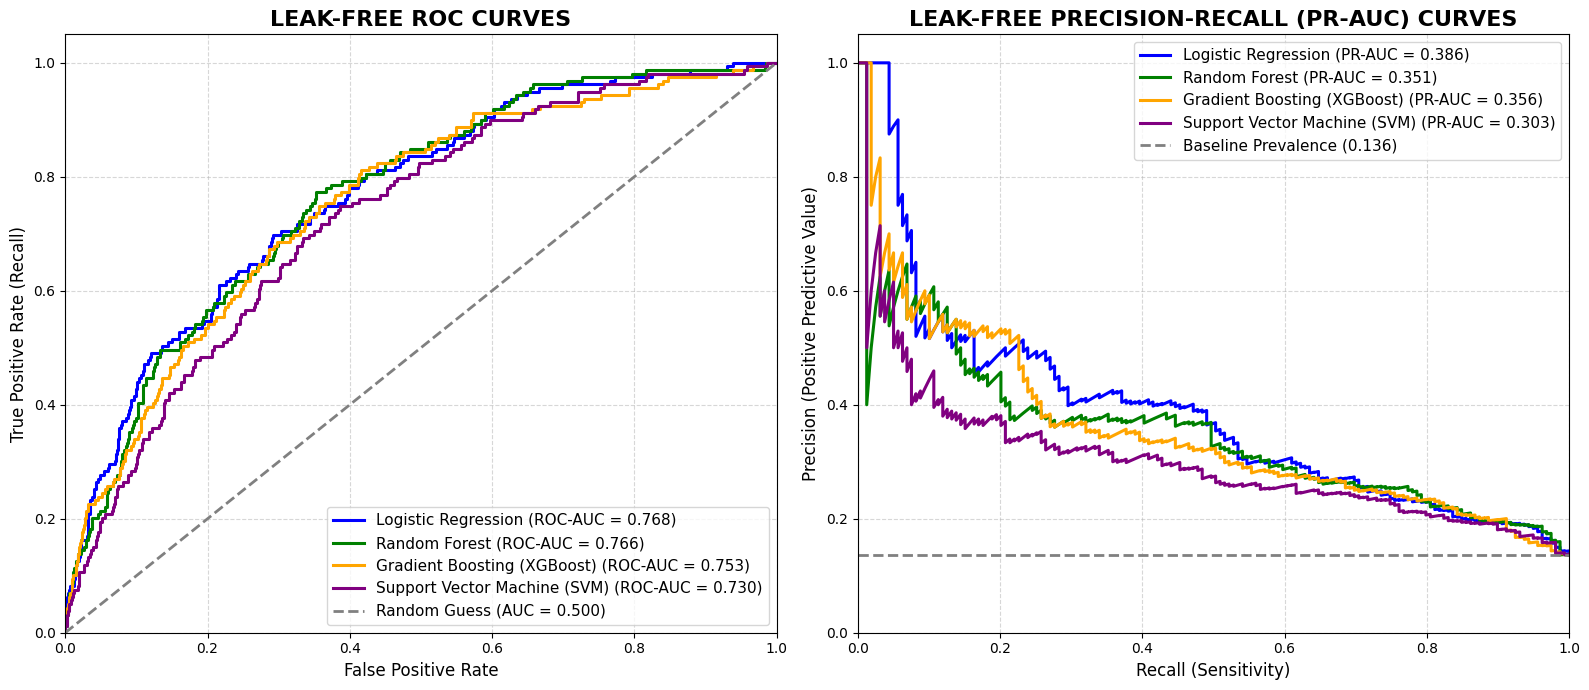

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, roc_curve, auc
)
from imblearn.combine import SMOTETomek
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

print("5-Fold Stratified Cross-Validation...")

# Start from the untouched raw dataset (drop only patient_id)
clean_raw_df = raw_dataset.drop(columns=['patient_id'], errors='ignore').copy()
y_all = clean_raw_df['mace'].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_names = [
    'Logistic Regression',
    'Random Forest',
    'Gradient Boosting (XGBoost)',
    'Support Vector Machine (SVM)'
]

results = {name: {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'roc_auc': [], 'pr_auc': []} for name in model_names}
fold_cms = {name: [] for name in model_names}
true_labels_all = []
lr_probs_all, rf_probs_all, xgb_probs_all, svm_probs_all = [], [], [], []

def get_leak_free_threshold(model_builder, X_tr_sc, y_tr, inner_splits=3):
    inner_skf = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=42)
    oof_probs = np.zeros(len(y_tr))
    for i_tr, i_val in inner_skf.split(X_tr_sc, y_tr):
        smote_inner = SMOTETomek(random_state=42)
        X_i_res, y_i_res = smote_inner.fit_resample(X_tr_sc[i_tr], y_tr[i_tr])
        model_inner = model_builder()
        model_inner.fit(X_i_res, y_i_res)
        oof_probs[i_val] = model_inner.predict_proba(X_tr_sc[i_val])[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(y_tr, oof_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores[:-1]) if len(thresholds) > 0 else 0
    return thresholds[best_idx] if len(thresholds) > 0 else 0.5

fold_no = 1
for train_index, val_index in skf.split(clean_raw_df, y_all):
    print(f"Processing Fold {fold_no}")

    # Split raw dataframe into isolated train and validation folds FIRST
    train_df = clean_raw_df.iloc[train_index].copy()
    val_df = clean_raw_df.iloc[val_index].copy()

    train_df['reperfusion'] = train_df['reperfusion'].fillna('None')
    val_df['reperfusion'] = val_df['reperfusion'].fillna('None')

    # Physiological LVEF formula applied row-wise
    for df_part in [train_df, val_df]:
        is_stemi = (df_part['acs_type'] == 'STEMI').astype(int)
        lvef_est = np.clip(
            52.0 - 3.5 * (df_part['killip_class'] - 1) - 4.0 * (df_part['heart_rate'] / df_part['systolic_bp']) - 5.1 * is_stemi,
            15.0, 70.0
        )
        df_part['lvef_percent'] = df_part['lvef_percent'].fillna(lvef_est).round(1)

    lab_cols = ['troponin_ng_ml', 'ckmb_u_l', 'ldl_mmol_l', 'hdl_mmol_l']
    for col in lab_cols:
        train_group_medians = train_df.groupby('acs_type')[col].median()
        train_global_median = train_df[col].median()
        train_df[col] = train_df[col].fillna(train_df['acs_type'].map(train_group_medians)).fillna(train_global_median)
        val_df[col] = val_df[col].fillna(val_df['acs_type'].map(train_group_medians)).fillna(train_global_median)

    sex_map = {'Female': 0, 'Male': 1}
    train_df['sex'] = train_df['sex'].map(sex_map)
    val_df['sex'] = val_df['sex'].map(sex_map)

    train_df = pd.get_dummies(train_df, columns=['acs_type', 'reperfusion'], drop_first=True, dtype=int)
    val_df = pd.get_dummies(val_df, columns=['acs_type', 'reperfusion'], drop_first=True, dtype=int)
    val_df = val_df.reindex(columns=train_df.columns, fill_value=0)

    X_tr_vif = train_df.drop(columns=['mace'])
    while True:
        df_const = add_constant(X_tr_vif)
        vifs = [variance_inflation_factor(df_const.values, i) for i in range(df_const.shape[1])]
        vif_series = pd.Series(vifs, index=df_const.columns).drop('const')
        if vif_series.max() > 10.0:
            X_tr_vif = X_tr_vif.drop(columns=[vif_series.idxmax()])
        else:
            break

    surviving_cols = X_tr_vif.columns.tolist()
    spearman_tr = train_df[surviving_cols + ['mace']].corr(method='spearman')['mace']
    selected_cols = [c for c in surviving_cols if abs(spearman_tr[c]) >= 0.02]

    X_train_fold = train_df[selected_cols].values
    y_train_fold = train_df['mace'].values
    X_val_fold = val_df[selected_cols].values
    y_val_fold = val_df['mace'].values

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_val_scaled = scaler.transform(X_val_fold)
    smote_tomek = SMOTETomek(random_state=42)
    X_train_res, y_train_res = smote_tomek.fit_resample(X_train_scaled, y_train_fold)

    lr_builder = lambda: LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    rf_builder = lambda: RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=4, class_weight='balanced', random_state=42)
    xgb_builder = lambda: XGBClassifier(n_estimators=120, learning_rate=0.05, max_depth=3, eval_metric='logloss', random_state=42)
    svm_builder = lambda: SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=42)

    # Tune probability thresholds strictly on training fold via inner CV
    lr_th = get_leak_free_threshold(lr_builder, X_train_scaled, y_train_fold)
    rf_th = get_leak_free_threshold(rf_builder, X_train_scaled, y_train_fold)
    xgb_th = get_leak_free_threshold(xgb_builder, X_train_scaled, y_train_fold)
    svm_th = get_leak_free_threshold(svm_builder, X_train_scaled, y_train_fold)

    # Fit final fold models on resampled training data and predict on validation fold
    lr = lr_builder(); lr.fit(X_train_res, y_train_res)
    lr_prob = lr.predict_proba(X_val_scaled)[:, 1]
    lr_pred = (lr_prob >= lr_th).astype(int)

    rf = rf_builder(); rf.fit(X_train_res, y_train_res)
    rf_prob = rf.predict_proba(X_val_scaled)[:, 1]
    rf_pred = (rf_prob >= rf_th).astype(int)

    xgb = xgb_builder(); xgb.fit(X_train_res, y_train_res)
    xgb_prob = xgb.predict_proba(X_val_scaled)[:, 1]
    xgb_pred = (xgb_prob >= xgb_th).astype(int)

    svm = svm_builder(); svm.fit(X_train_res, y_train_res)
    svm_prob = svm.predict_proba(X_val_scaled)[:, 1]
    svm_pred = (svm_prob >= svm_th).astype(int)

    for name, pred, prob in [
        ('Logistic Regression', lr_pred, lr_prob),
        ('Random Forest', rf_pred, rf_prob),
        ('Gradient Boosting (XGBoost)', xgb_pred, xgb_prob),
        ('Support Vector Machine (SVM)', svm_pred, svm_prob)
    ]:
        results[name]['acc'].append(accuracy_score(y_val_fold, pred))
        results[name]['prec'].append(precision_score(y_val_fold, pred, zero_division=0))
        results[name]['rec'].append(recall_score(y_val_fold, pred))
        results[name]['f1'].append(f1_score(y_val_fold, pred))
        results[name]['roc_auc'].append(roc_auc_score(y_val_fold, prob))
        results[name]['pr_auc'].append(average_precision_score(y_val_fold, prob))
        fold_cms[name].append(confusion_matrix(y_val_fold, pred))

    lr_probs_all.extend(lr_prob)
    rf_probs_all.extend(rf_prob)
    xgb_probs_all.extend(xgb_prob)
    svm_probs_all.extend(svm_prob)
    true_labels_all.extend(y_val_fold)
    fold_no += 1

final_metrics = {
    name: {
        'Accuracy': np.mean(results[name]['acc']),
        'Precision': np.mean(results[name]['prec']),
        'Recall': np.mean(results[name]['rec']),
        'F1 Score': np.mean(results[name]['f1']),
        'ROC-AUC': np.mean(results[name]['roc_auc']),
        'PR-AUC': np.mean(results[name]['pr_auc'])
    }
    for name in model_names
}

comparison_df = pd.DataFrame(final_metrics).T
print("\nModel Comparison (5-Fold CV)")
display(comparison_df.round(4))

true_labels_all = np.array(true_labels_all)
lr_probs_all = np.array(lr_probs_all)
rf_probs_all = np.array(rf_probs_all)
xgb_probs_all = np.array(xgb_probs_all)
svm_probs_all = np.array(svm_probs_all)

# Plotting Leak-Free Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()
cmaps = ['Blues', 'Greens', 'Oranges', 'Purples']

for i, name in enumerate(model_names):
    avg_cm = np.mean(fold_cms[name], axis=0)
    sns.heatmap(avg_cm, annot=True, fmt='.1f', cmap=cmaps[i], ax=axes[i], cbar=False, annot_kws={"size": 14, "weight": "bold"})
    axes[i].set_title(f'{name} (Leak-Free Averaged CM)', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=12)
    axes[i].set_ylabel('True Label', fontsize=12)
    axes[i].set_xticklabels(['No MACE (0)', 'MACE (1)'])
    axes[i].set_yticklabels(['No MACE (0)', 'MACE (1)'])

plt.tight_layout()
plt.show()

# Plotting ROC-AUC and PR-AUC Curves Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
models_probs = [
    ('Logistic Regression', lr_probs_all, 'blue'),
    ('Random Forest', rf_probs_all, 'green'),
    ('Gradient Boosting (XGBoost)', xgb_probs_all, 'orange'),
    ('Support Vector Machine (SVM)', svm_probs_all, 'purple')
]

for name, y_prob, color in models_probs:
    fpr, tpr, _ = roc_curve(true_labels_all, y_prob)
    roc_auc_val = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=color, lw=2.2, label=f'{name} (ROC-AUC = {roc_auc_val:.3f})')

    prec_c, rec_c, _ = precision_recall_curve(true_labels_all, y_prob)
    pr_auc_val = average_precision_score(true_labels_all, y_prob)
    axes[1].plot(rec_c, prec_c, color=color, lw=2.2, label=f'{name} (PR-AUC = {pr_auc_val:.3f})')

axes[0].plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess (AUC = 0.500)')
axes[0].set_xlim([0.0, 1.0]); axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[0].set_title('LEAK-FREE ROC CURVES', fontsize=16, fontweight='bold')
axes[0].legend(loc="lower right", fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

baseline_prevalence = true_labels_all.mean()
axes[1].axhline(y=baseline_prevalence, color='gray', lw=2, linestyle='--', label=f'Baseline Prevalence ({baseline_prevalence:.3f})')
axes[1].set_xlim([0.0, 1.0]); axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall (Sensitivity)', fontsize=12)
axes[1].set_ylabel('Precision (Positive Predictive Value)', fontsize=12)
axes[1].set_title('LEAK-FREE PRECISION-RECALL (PR-AUC) CURVES', fontsize=16, fontweight='bold')
axes[1].legend(loc="upper right", fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()